In [18]:
from langgraph.graph import StateGraph, START, END
from typing import Literal
from langgraph.types import interrupt, Command
from langchain_groq import ChatGroq
from dotenv import load_dotenv
import os
from pydantic import BaseModel
from langgraph.checkpoint.memory import InMemorySaver

In [10]:
load_dotenv()

model = os.getenv('GROQ_MODEL')
api_key = os.getenv('GROQ_API_KEY')

llm = ChatGroq(model=model, api_key=api_key)

In [13]:
class OrderState(BaseModel):
    name: str = ""
    price: int = 0
    is_confirmed: bool = False

In [23]:
def show_order(state: OrderState)-> OrderState:
    print(f"------- Product Name: {state.name} -------")
    print(f"------ Product Price: {state.price} ------")
    return state

def user_confirmation(state: OrderState)-> OrderState:
    res = interrupt({
        "question":"Do you want to confirm this order (type 'yes' or 'no')"
    })

    state.is_confirmed = res.lower() == "yes"

    return state

def router(state: OrderState)-> Literal["confirm", "cancel"]:
    if state.is_confirmed:
        return "confirm"
    return "cancel"

def confirm_order(state: OrderState)-> OrderState:
    print(f"Your Order: {state.name} is Confirmed")
    return state

def cancel_order(state: OrderState)-> OrderState:
    print(f"Your Order: {state.name} is Cancelled")
    return state

In [24]:
graph = StateGraph(OrderState)

graph.add_node("show", show_order)
graph.add_node("user_confirmation", user_confirmation)
graph.add_node("confirm", confirm_order)
graph.add_node("cancel", cancel_order)

graph.add_edge(START, "show")
graph.add_edge("show", "user_confirmation")
graph.add_conditional_edges("user_confirmation", router)
graph.add_edge("confirm", END)
graph.add_edge("cancel", END)

app = graph.compile(checkpointer=InMemorySaver())

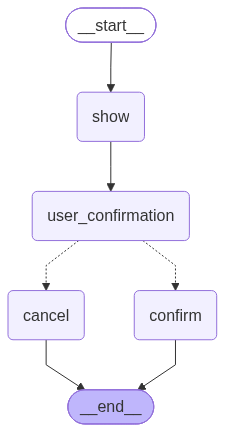

In [25]:
app

In [35]:
res = app.invoke({"name":"iPhone 25 pro max", "price":70000},{'configurable':{'thread_id':'1'}})

------- Product Name: iPhone 25 pro max -------
------ Product Price: 70000 ------


In [36]:
res = app.invoke(Command(resume="yes"),{'configurable':{'thread_id':'1'}})

Your Order: iPhone 25 pro max is Confirmed
